In [2]:
import jax.numpy as jnp
import blackjax
import ripplegw
import matplotlib.pyplot as plt

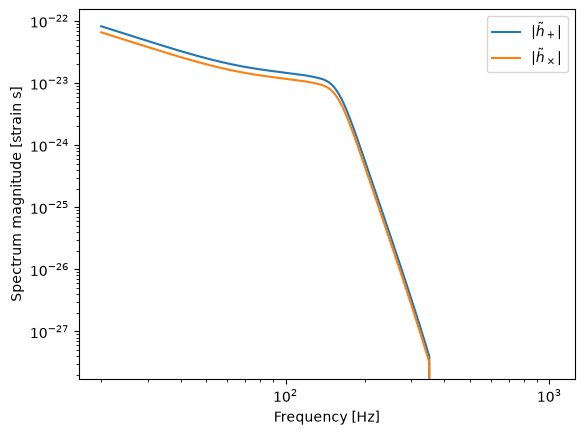

In [57]:
frequency = jnp.arange(20.0, 1024.0, 0.25)

# GW150914-like binary black hole parameters

mass_values = [50]

for i in mass_values:
    params = {
    "M_c": i,   # chirp mass [solar masses]
    "eta": 0.247,  # symmetric mass ratio
    "s1_z": 0.0,   # primary aligned spin
    "s2_z": 0.0,   # secondary aligned spin
    "d_L": 400,  # luminosity distance [Mpc]
    "phase_c": 0.0,
    "iota": jnp.pi/3,
    }


    # Construct the waveform model by its registered name
    waveform = ripplegw.waveform("IMRPhenomD", f_ref=20)

    # Evaluate: returns a dict with keys "p" (h_+) and "c" (h_x)
    polarizations = waveform(frequency, params)

    hp = polarizations["p"]
    hc = polarizations["c"]

    plt.loglog(frequency, jnp.abs(hp), label=r"$|\tilde h_+|$")
    plt.loglog(frequency, jnp.abs(hc), label=r"$|\tilde h_\times|$")

plt.xlabel("Frequency [Hz]")
plt.ylabel("Spectrum magnitude [strain s]")
plt.legend()
plt.show()


params = {
"M_c": 30,   # chirp mass [solar masses]
"eta": 0.247,  # symmetric mass ratio
"s1_z": 0.0,   # primary aligned spin
"s2_z": 0.0,   # secondary aligned spin
"d_L": 400,  # luminosity distance [Mpc]
"phase_c": 0.0,
"iota": jnp.pi/3,
}

# Construct the waveform model by its registered name
waveform = ripplegw.waveform("IMRPhenomD", f_ref=20)

# Evaluate: returns a dict with keys "p" (h_+) and "c" (h_x)
polarizations = waveform(frequency, params)

hp_1 = polarizations["p"]
hc_1 = polarizations["c"]


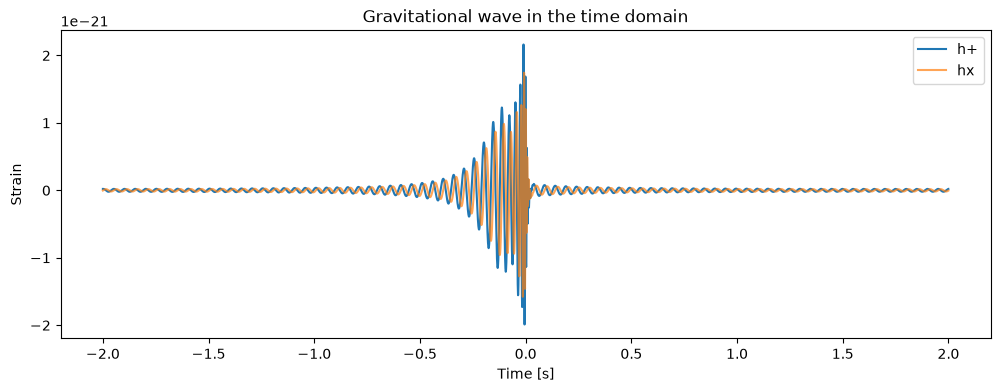

In [58]:
df = 0.25

N = 8192

full_frequency = jnp.arange(0, 1024.25, df)

def h_to_htime_shift(h, df, N, shift: float = 0):
    h_full = jnp.pad(h, (80,1))
    h_shifted_f = h_full * jnp.exp(-2j * jnp.pi * full_frequency * shift)
    h_time = jnp.fft.irfft(h_shifted_f, n=N) * (N * df)    
    return h_time
    
#First wave
hp_time = h_to_htime_shift(hp, df, N, shift = 2)
hc_time = h_to_htime_shift(hc, df, N, shift = 2)

#second wave - mass 30
hp_1_time = h_to_htime_shift(hp_1, df, N, shift =2.5)
hc_1_time = h_to_htime_shift(hc_1, df, N, shift =2.5)

# Construct the time axis
dt = 1 / 2048
time = (jnp.arange(N) - N // 2) * dt

# Plot
plt.figure(figsize=(12, 4))
plt.plot(time, hp_time, label="h+")
plt.plot(time, hc_time, label="hx", alpha=0.7)

plt.xlabel("Time [s]")
plt.ylabel("Strain")
plt.title("Gravitational wave in the time domain")
plt.legend()
plt.show()

plot second wave

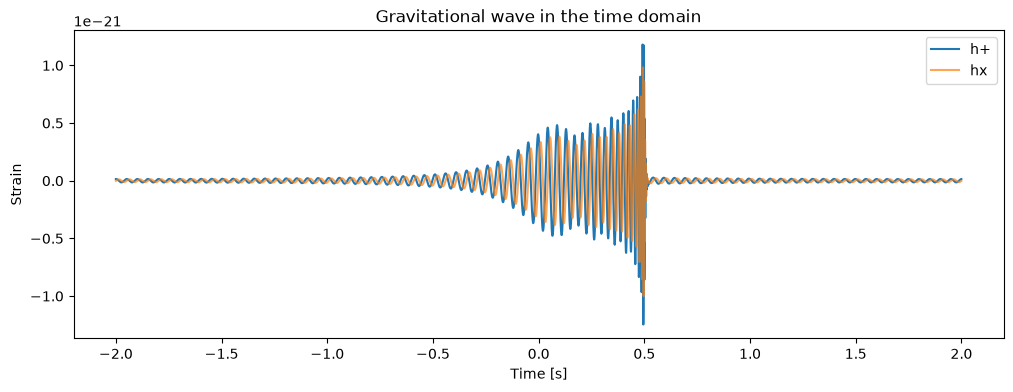

In [59]:
plt.figure(figsize=(12, 4))
plt.plot(time, hp_1_time, label="h+")
plt.plot(time, hc_1_time, label="hx", alpha=0.7)

plt.xlabel("Time [s]")
plt.ylabel("Strain")
plt.title("Gravitational wave in the time domain")
plt.legend()
plt.show()

overlapping signal

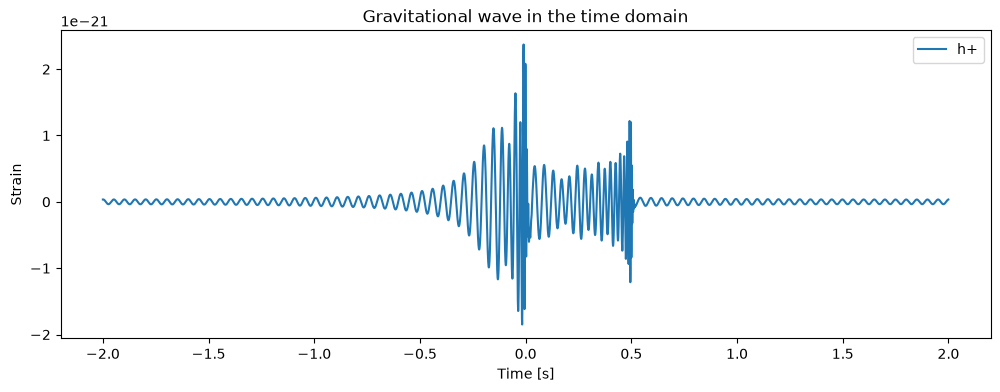

In [60]:
overlapping_hp = hp_time +hp_1_time
overlapping_hc = hc_time + hc_1_time


plt.figure(figsize=(12, 4))
plt.plot(time, overlapping_hp, label="h+")
#plt.plot(time, overlapping_hc, label="hx", alpha=0.6)

plt.xlabel("Time [s]")
plt.ylabel("Strain")
plt.title("Gravitational wave in the time domain")
plt.legend()
plt.show()

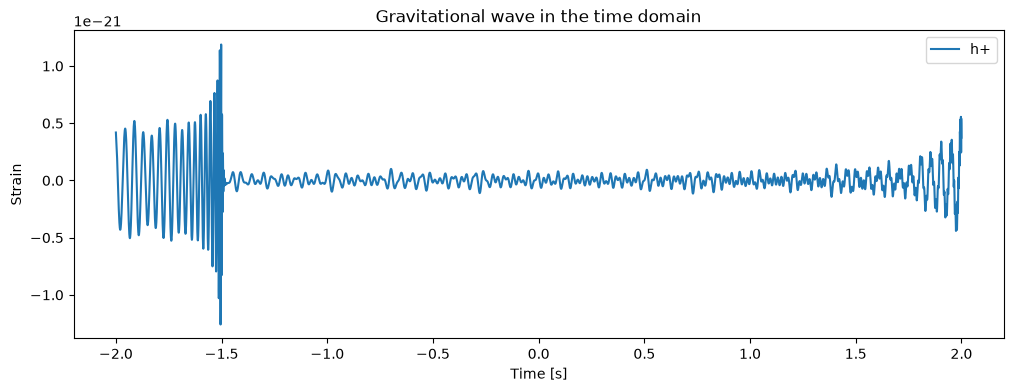

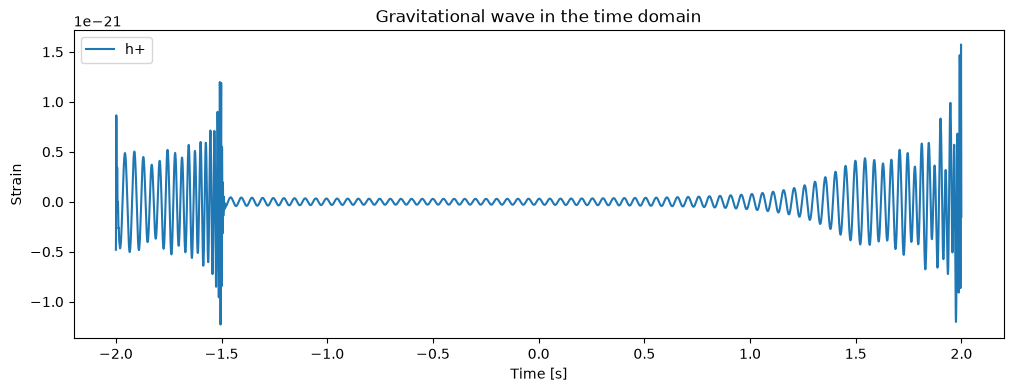

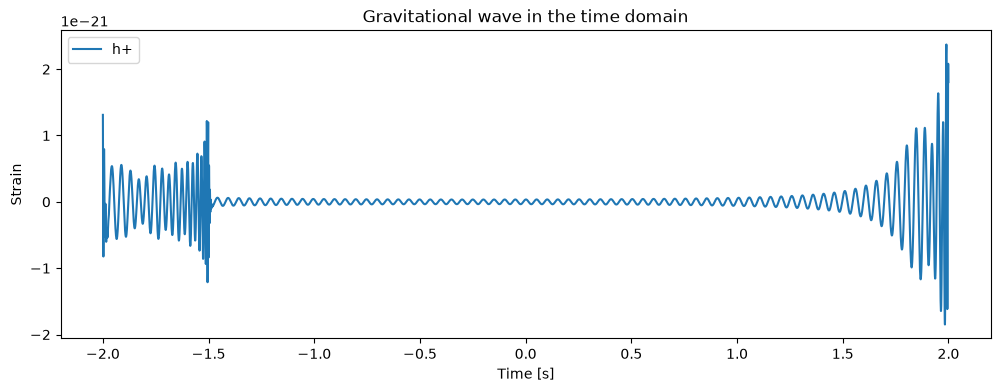

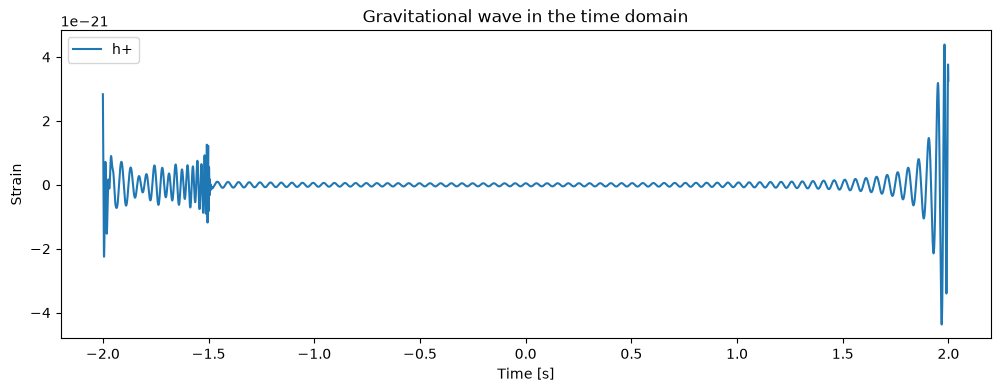

In [ ]:
frequency = jnp.arange(20.0, 1024.0, 0.25)

def h_to_htime_shift(h, df, N, shift: float = 0):
    h_full = jnp.pad(h, (80,1))
    h_shifted_f = h_full * jnp.exp(-2j * jnp.pi * full_frequency * shift)
    h_time = jnp.fft.irfft(h_shifted_f, n=N) * (N * df)    
    return h_time

# GW150914-like binary black hole parameters

mass_values = [5, 30 ,50, 100]

for i in mass_values:
    params = {
    "M_c": i,   # chirp mass [solar masses]
    "eta": 0.247,  # symmetric mass ratio
    "s1_z": 0.0,   # primary aligned spin
    "s2_z": 0.0,   # secondary aligned spin
    "d_L": 400,  # luminosity distance [Mpc]
    "phase_c": 0.0,
    "iota": jnp.pi/3,
    }


    # Construct the waveform model by its registered name
    waveform = ripplegw.waveform("IMRPhenomD", f_ref=20)

    # Evaluate: returns a dict with keys "p" (h_+) and "c" (h_x)
    polarizations = waveform(frequency, params)

    hp = polarizations["p"]
    hc = polarizations["c"]

    params = {
    "M_c": 30,   # chirp mass [solar masses]
    "eta": 0.247,  # symmetric mass ratio
    "s1_z": 0.0,   # primary aligned spin
    "s2_z": 0.0,   # secondary aligned spin
    "d_L": 400,  # luminosity distance [Mpc]
    "phase_c": 0.0,
    "iota": jnp.pi/3,
    }

    # Construct the waveform model by its registered name
    waveform = ripplegw.waveform("IMRPhenomD", f_ref=20)

    # Evaluate: returns a dict with keys "p" (h_+) and "c" (h_x)
    polarizations = waveform(frequency, params)

    hp_1 = polarizations["p"]
    hc_1 = polarizations["c"]


    df = 0.25

    N = 8192

    full_frequency = jnp.arange(0, 1024.25, df)
        
    #First wave
    hp_time = h_to_htime_shift(hp, df, N)
    hc_time = h_to_htime_shift(hc, df, N)

    #second wave - mass 30
    hp_1_time = h_to_htime_shift(hp_1, df, N, shift =0.5)
    hc_1_time = h_to_htime_shift(hc_1, df, N, shift =0.5)

    # Construct the time axis
    dt = 1 / 2048
    time = (jnp.arange(N) - N // 2) * dt

    overlapping_hp = hp_time +hp_1_time
    overlapping_hc = hc_time + hc_1_time


    plt.figure(figsize=(12, 4))
    plt.plot(time, overlapping_hp, label="h+")
    #plt.plot(time, overlapping_hc, label="hx", alpha=0.6)

    plt.xlabel("Time [s]")
    plt.ylabel("Strain")
    plt.title("Gravitational wave in the time domain")
    plt.legend()
    plt.show()

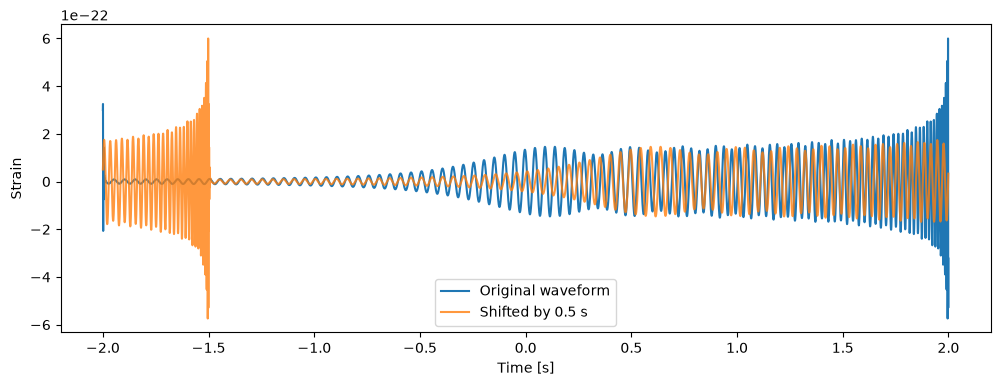

In [16]:
# Shift by 0.5 seconds
delta_t = 0.5

# Apply time shift in frequency domain
hp_shifted_f = hp_full * jnp.exp(
    -2j * jnp.pi * full_frequency * delta_t
)

# Convert shifted signal to time domain
hp_shifted_t = jnp.fft.irfft(hp_shifted_f, n=N) * (N * df)


# Compare
plt.figure(figsize=(12, 4))

plt.plot(time, hp_time, label="Original waveform")
plt.plot(time, hp_shifted_t, label="Shifted by 0.5 s", alpha=0.8)

plt.xlabel("Time [s]")
plt.ylabel("Strain")
plt.legend()
plt.show()

## 1. Generate two different Ripple waveforms

Use the same IMRPhenomD model and frequency grid as above. Binary A keeps its
chirp mass of $15\,M_\odot$, while binary B has $30\,M_\odot$. Both share
the same mass ratio, spins, distance, phase and inclination. Use the plus
polarization as a single strain channel for this example.

Ripple returns complex frequency-domain strain $\tilde h_+(f)$. Pad both
spectra onto the same real-FFT grid and use an inverse FFT to see the two
chirps in time. The factors $\Delta t_{\rm sample}$ and $1/\Delta t_{\rm sample}$
in the forward and inverse transforms give spectra in strain-seconds and
time series in strain. [Ripple waveform guide](https://gw-jax-team.github.io/ripple/latest/guides/waveforms/)
· [FFT conventions](https://numpy.org/doc/stable/reference/routines.fft.html)

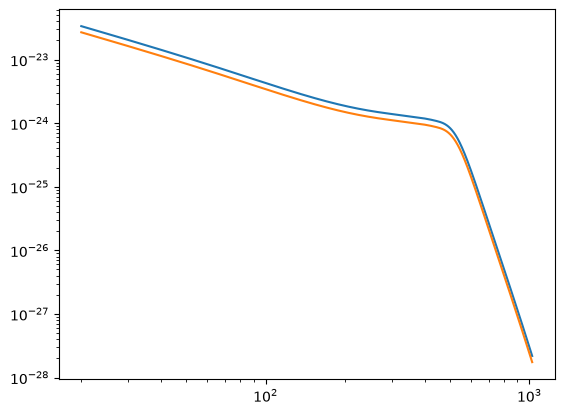

In [8]:
import jax.numpy as jnp
import blackjax
import ripplegw
import matplotlib.pyplot as plt

frequency = jnp.arange(20.0, 1024.0, 0.25)

# GW150914-like binary black hole parameters

mass_values = [15]

for i in mass_values:
    params = {
    "M_c": i,   # chirp mass [solar masses]
    "eta": 0.247,  # symmetric mass ratio
    "s1_z": 0.0,   # primary aligned spin
    "s2_z": 0.0,   # secondary aligned spin
    "d_L": 400,  # luminosity distance [Mpc]
    "phase_c": 0.0,
    "iota": jnp.pi/3,
    }


    # Construct the waveform model by its registered name
    waveform = ripplegw.waveform("IMRPhenomD", f_ref=20)

    # Evaluate: returns a dict with keys "p" (h_+) and "c" (h_x)
    polarizations = waveform(frequency, params)

    hp = polarizations["p"]
    hc = polarizations["c"]

    plt.loglog(frequency, jnp.abs(hp), label=r"$|\tilde h_+|$")
    plt.loglog(frequency, jnp.abs(hc), label=r"$|\tilde h_\times|$")

In [ ]:
def to_time(spectrum):
    return jnp.fft.fftshift(jnp.fft.irfft(spectrum, n=N)) 

In [ ]:
import numpy as np





def to_frequency(freq_wave):
    return dt * jnp.fft.rfft(jnp.fft.ifftshift(freq_wave), n=N)


def delay_factor(frequencies_hz, delay_s):
    return jnp.exp(-2j * jnp.pi * frequencies_hz * delay_s)


mass_a = params["M_c"]
mass_b = 30.0
spectrum_a = hp_full
# Place the modeled bins on the full FFT grid and leave the rest zero.
ripple_bins = (frequency[0] <= full_frequency) & (full_frequency <= frequency[-1])
spectrum_b = jnp.zeros_like(spectrum_a).at[ripple_bins].set(plus_spectrum(frequency, mass_b))
strain_a = to_time(spectrum_a)

## 2. Change the overlap with a relative time delay

Keep A fixed and multiply B by the phase ramp $e^{-2\pi i f \tau}$, where
$\tau$ is the delay in seconds. With this FFT convention a positive $\tau$
moves B later in time, and the ramp has unit magnitude at every frequency.
The FFT treats the 4 s time window as periodic, so keep the chirps away
from the window boundaries when trying larger delays.

To quantify how much the signals coincide in time, compute the normalized
dot product of their amplitude envelopes. A value near 1 means their
envelopes line up closely. A value near 0 means little temporal overlap.
This statistic measures timing even when the two chirps oscillate at
different phases. [Amplitude envelopes with the Hilbert transform](https://docs.scipy.org/doc/scipy/reference/generated/scipy.signal.hilbert.html)

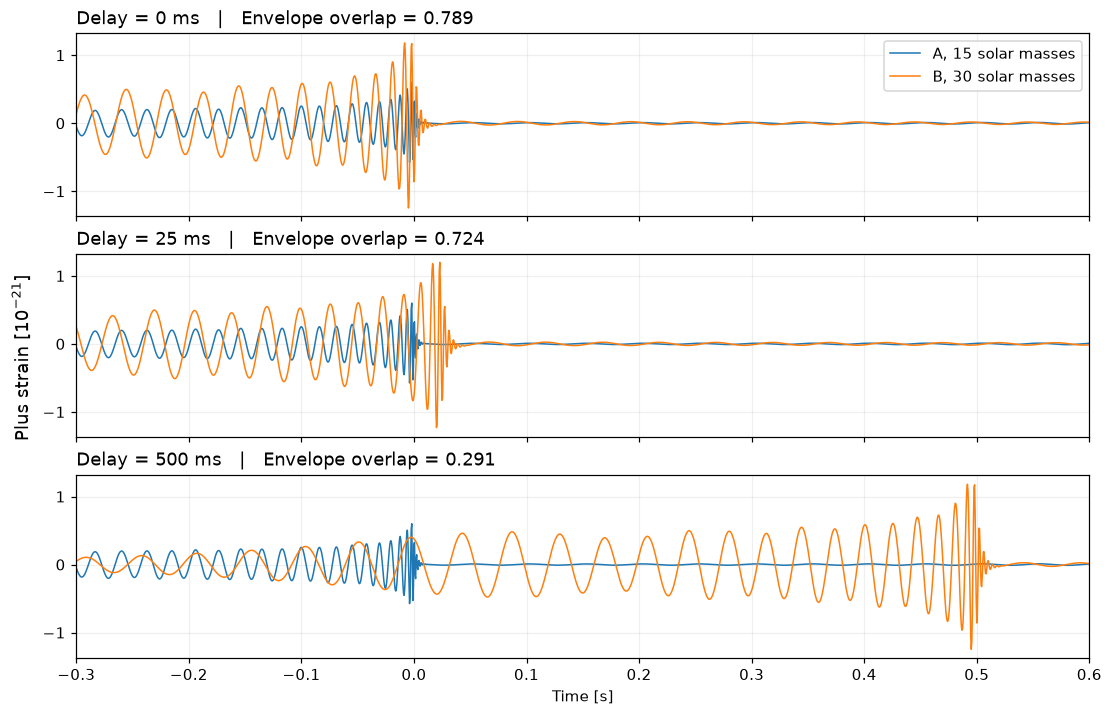

In [6]:
delay_s = 0.025  # Change this value to try a different injection in sections 2–4.
delays_s = (0.0, delay_s, 0.50)
time_window_s = (min(delays_s) - 0.30, max(delays_s) + 0.10)

# Normalize before computing envelope norms at gravitational-wave strain scales.
strain_scale = 1e-21
envelope_a = np.abs(hilbert(np.asarray(strain_a / strain_scale)))


def envelope_overlap(strain_b):
    envelope_b = np.abs(hilbert(np.asarray(strain_b / strain_scale)))
    return np.dot(envelope_a, envelope_b) / (
        np.linalg.norm(envelope_a) * np.linalg.norm(envelope_b)
    )

fig, axes = plt.subplots(3, 1, figsize=(10, 6.4), sharex=True, sharey=True, layout="constrained")
overlaps = []
for ax, delay in zip(axes, delays_s):
    strain_b_at_delay = to_time(spectrum_b * delay_factor(full_frequency, delay))
    overlap = envelope_overlap(strain_b_at_delay)
    overlaps.append(overlap)
    ax.plot(time, strain_a / strain_scale, label=f"A, {mass_a:g} solar masses", lw=1)
    ax.plot(time, strain_b_at_delay / strain_scale, label=f"B, {mass_b:g} solar masses", lw=1)
    ax.set_title(f"Delay = {delay * 1000:g} ms   |   Envelope overlap = {overlap:.3f}", loc="left")
    ax.grid(alpha=0.2)

axes[0].legend(loc="upper right")
axes[-1].set(xlabel="Time [s]", xlim=time_window_s)
fig.supylabel(r"Plus strain [$10^{-21}$]")
plt.show()

## 3. Fourier transform each chirp and add the spectra

Take the forward FFT of each real time series using the selected delay
above. Add the **complex** spectra bin by bin, then take the magnitude for
the plot. The relative phase determines where the two spectra reinforce
or cancel. Linearity gives

$$
\tilde h_{\rm total}(f)
  = \tilde h_A(f) + e^{-2\pi i f\tau}\tilde h_B(f)
  = \mathcal{F}[h_A(t) + h_B(t-\tau)].
$$

Check both this equality and the inverse transform back to the summed
time series.

Relative max error, FFT round trip: 1.47e-07
Relative max error, FFT of sum vs sum of FFTs: 1.03e-07
Relative max error, inverse FFT of summed spectra: 1.48e-07


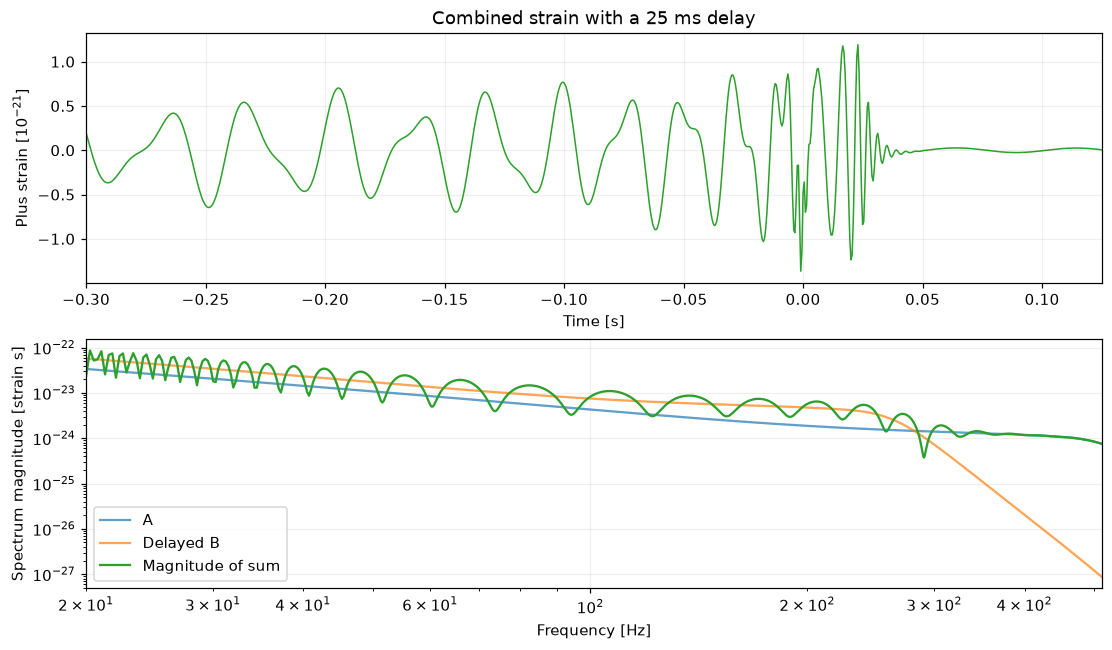

In [7]:
spectrum_b_delayed = spectrum_b * delay_factor(full_frequency, delay_s)
strain_b_delayed = to_time(spectrum_b_delayed)

fft_a = to_frequency(strain_a)
fft_b = to_frequency(strain_b_delayed)
combined_f = fft_a + fft_b
combined_t = strain_a + strain_b_delayed

round_trip_error = jnp.max(jnp.abs(combined_f - (spectrum_a + spectrum_b_delayed))) / jnp.max(
    jnp.abs(combined_f)
)
fft_sum_error = jnp.max(jnp.abs(to_frequency(combined_t) - combined_f)) / jnp.max(jnp.abs(combined_f))
ifft_sum_error = jnp.max(jnp.abs(to_time(combined_f) - combined_t)) / jnp.max(jnp.abs(combined_t))
print(f"Relative max error, FFT round trip: {round_trip_error:.2e}")
print(f"Relative max error, FFT of sum vs sum of FFTs: {fft_sum_error:.2e}")
print(f"Relative max error, inverse FFT of summed spectra: {ifft_sum_error:.2e}")

plot_band = ripple_bins & (full_frequency <= 512.0)
fig, (ax_time, ax_freq) = plt.subplots(2, 1, figsize=(10, 5.8), layout="constrained")
ax_time.plot(time, combined_t / strain_scale, color="C2", lw=1)
ax_time.set(
    title=f"Combined strain with a {delay_s * 1000:g} ms delay",
    xlabel="Time [s]",
    ylabel=r"Plus strain [$10^{-21}$]",
    xlim=(min(0.0, delay_s) - 0.30, max(0.0, delay_s) + 0.10),
)

ax_freq.loglog(full_frequency[plot_band], jnp.abs(fft_a[plot_band]), label="A", alpha=0.7)
ax_freq.loglog(full_frequency[plot_band], jnp.abs(fft_b[plot_band]), label="Delayed B", alpha=0.7)
ax_freq.loglog(full_frequency[plot_band], jnp.abs(combined_f[plot_band]), label="Magnitude of sum", color="C2")
ax_freq.set(xlabel="Frequency [Hz]", ylabel="Spectrum magnitude [strain s]", xlim=(20, 512))
ax_freq.legend()
for ax in (ax_time, ax_freq):
    ax.grid(alpha=0.2)
plt.show()

## 4. Recover the two chirp masses and delay with nested sampling (optional)

Make mock data by adding seeded Gaussian noise to the summed spectrum from
section 3. Fit both chirp masses and the relative delay jointly with BlackJAX
nested slice sampling. Anchor A's time at zero and hold the other source
parameters fixed. Use local uniform priors for the two masses and the delay
so this is a first recovery around a candidate pair of signals. If you
change the injection, check that the parameters still fall inside the
bounds in `prior_min` and `prior_max`.

In the 20–256 Hz analysis band, use independent Gaussian noise of equal
variance $\sigma^2$ in the real and imaginary parts of every bin. For data
$\tilde d_k$ and the summed template $\tilde h_k(\theta)$, this gives

$$
\log L(\theta) = -\frac{1}{2\sigma^2}
  \sum_k |\tilde d_k-\tilde h_k(\theta)|^2 + \text{const}.
$$

Section 5 repeats the fit at different delays. For detector data, a noise
power spectral density would set the weight of each frequency bin.
[BlackJAX nested slice sampling](https://blackjax-devs.github.io/blackjax/autoapi/blackjax/ns/nss/index.html)

In [8]:
import jax
from blackjax.ns.utils import finalise, sample

fit_band = ripple_bins & (full_frequency <= 256.0)
fit_frequency = full_frequency[fit_band]
spectral_scale = 1e-23
# All amplitudes in the likelihood are measured in units of spectral_scale.
noise_std = 1.4

prior_min = jnp.array([14.75, 28.8, 0.016])
prior_max = jnp.array([15.30, 31.0, 0.035])

display_scale = np.array([1.0, 1.0, 1000.0])
labels = [r"A chirp mass [$M_\odot$]", r"B chirp mass [$M_\odot$]", "B delay [ms]"]


def draw_noise(key):
    key, real_key, imag_key = jax.random.split(key, 3)
    noise = noise_std * (
        jax.random.normal(real_key, fit_frequency.shape)
        + 1j * jax.random.normal(imag_key, fit_frequency.shape)
    )
    return key, noise


def physical_parameters(unit_position, lower, upper):
    return lower + (upper - lower) * unit_position


def logprior(unit_position):
    inside = jnp.all((0.0 <= unit_position) & (unit_position <= 1.0))
    return jnp.where(inside, 0.0, -jnp.inf)


def make_sampler(observed, lower, upper):
    def loglikelihood(unit_position):
        # Map the unit cube to physical parameters, even for rejected proposals.
        m_a, m_b, delay = physical_parameters(jnp.clip(unit_position, 0.0, 1.0), lower, upper)
        template = (
            plus_spectrum(fit_frequency, m_a)
            + delay_factor(fit_frequency, delay) * plus_spectrum(fit_frequency, m_b)
        ) / spectral_scale
        residual = (observed - template) / noise_std
        # Keep points outside the prior out of the likelihood contour.
        return logprior(unit_position) - 0.5 * jnp.sum(jnp.abs(residual) ** 2)

    return blackjax.nss(
        logprior_fn=logprior,
        loglikelihood_fn=loglikelihood,
        num_delete=8,
        num_inner_steps=8,
    )


# Pass data and prior bounds as arrays so one compilation can serve the whole sweep.
@jax.jit
def init_live(positions, observed, lower, upper):
    return make_sampler(observed, lower, upper).init(positions)


@jax.jit
def step_live(key, live, observed, lower, upper):
    return make_sampler(observed, lower, upper).step(key, live)


def recover_parameters(key, observed, lower, upper):
    key, init_key = jax.random.split(key)
    live = init_live(jax.random.uniform(init_key, (128, 3)), observed, lower, upper)
    dead_points = []
    for _ in range(500):
        key, step_key = jax.random.split(key)
        live, dead = step_live(step_key, live, observed, lower, upper)
        dead_points.append(dead)
        if live.integrator.logZ_live - live.integrator.logZ < -3.0:
            break
    else:
        raise RuntimeError("The live evidence threshold was not reached within 500 steps.")

    run = finalise(live, dead_points, update_info=False)
    key, posterior_key = jax.random.split(key)
    positions = sample(posterior_key, run, shape=4000).position
    return np.asarray(physical_parameters(positions, lower, upper)), len(dead_points)

Stopped after 222 nested-sampling steps.
A chirp mass [solar masses]: 14.999 (90% credible interval 14.991 to 15.008), injected 15
B chirp mass [solar masses]: 30.009 (90% credible interval 29.945 to 30.069), injected 30
B delay [ms]: 25.064 (90% credible interval 24.816 to 25.347), injected 25


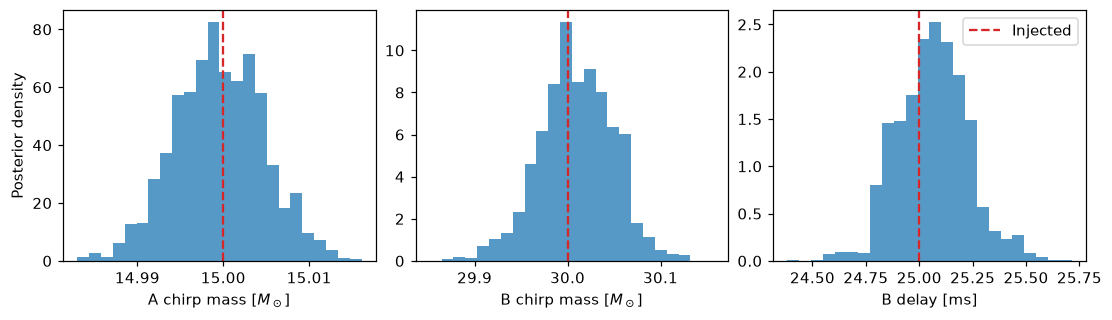

In [9]:
truth = np.array([mass_a, mass_b, delay_s])
if not np.all((prior_min <= truth) & (truth <= prior_max)):
    raise ValueError("The injection falls outside the priors. Adjust prior_min or prior_max.")

key, noise = draw_noise(jax.random.key(27))
observed_f = combined_f[fit_band] / spectral_scale + noise
posterior, steps = recover_parameters(key, observed_f, prior_min, prior_max)

scaled_posterior = posterior * display_scale
intervals = np.quantile(scaled_posterior, [0.05, 0.50, 0.95], axis=0)
summary_labels = ["A chirp mass [solar masses]", "B chirp mass [solar masses]", "B delay [ms]"]

print(f"Stopped after {steps} nested-sampling steps.")
fig, axes = plt.subplots(1, 3, figsize=(10, 2.8), layout="constrained")
for i, (ax, label) in enumerate(zip(axes, labels)):
    lower, median, upper = intervals[:, i]
    injected = truth[i] * display_scale[i]
    print(f"{summary_labels[i]}: "
          f"{median:.3f} (90% credible interval {lower:.3f} to {upper:.3f}), injected {injected:g}")
    ax.hist(scaled_posterior[:, i], bins=24, density=True, color="C0", alpha=0.75)
    ax.axvline(injected, color="C3", ls="--", label="Injected")
    ax.set_xlabel(label)

axes[0].set_ylabel("Posterior density")
axes[-1].legend()
plt.show()

## 5. How does overlap affect parameter recovery?

Inject the same two binaries at four delays and repeat the joint fit for
three Gaussian noise draws. Reuse each noise draw across all four delays
so the comparisons are paired. The chirp-mass priors stay fixed, and the
delay prior moves with the injection, keeping the same width and the same
offset from the true delay. This tests local recovery with a rough timing
estimate for each case. Run the setup cell in section 4 before starting the sweep, which can take several minutes.

- **Recovery error** is the absolute difference between the posterior
  median and the injected value. The summary uses root-mean-square error
  (RMSE) across the three draws.
- **Posterior uncertainty** is the width of the central 90% credible
  interval. The summary uses the median width across the three draws.

The envelope overlap describes when the signals coincide. The complex
phase relationships between them also change with delay and can influence
the fit. [Pizzati et al., *Toward inference of overlapping gravitational wave signals*](https://doi.org/10.1103/PhysRevD.105.104016)

In [10]:
sweep_delays_s = np.array([0.0, 0.025, 0.150, 0.500])
noise_seeds = (27, 83, 129)
noise_draws = [draw_noise(jax.random.key(seed)) for seed in noise_seeds]
sweep_overlaps = np.empty(len(sweep_delays_s))
# Axes are delay, noise draw, posterior quantile, and parameter.
sweep_quantiles = np.empty((len(sweep_delays_s), len(noise_draws), 3, 3))

for i, injected_delay in enumerate(sweep_delays_s):
    delayed_b = spectrum_b * delay_factor(full_frequency, injected_delay)
    sweep_overlaps[i] = envelope_overlap(to_time(delayed_b))
    clean_spectrum = (spectrum_a[fit_band] + delayed_b[fit_band]) / spectral_scale
    prior_shift = jnp.array([0.0, 0.0, injected_delay - delay_s])
    lower, upper = prior_min + prior_shift, prior_max + prior_shift

    for j, (sampler_key, noise_draw) in enumerate(noise_draws):
        draws, _ = recover_parameters(
            jax.random.fold_in(sampler_key, i), clean_spectrum + noise_draw, lower, upper
        )
        sweep_quantiles[i, j] = np.quantile(draws * display_scale, [0.05, 0.50, 0.95], axis=0)

    print(f"Finished {injected_delay * 1000:g} ms delay (overlap {sweep_overlaps[i]:.3f}).")

Finished 0 ms delay (overlap 0.789).
Finished 25 ms delay (overlap 0.724).
Finished 150 ms delay (overlap 0.578).
Finished 500 ms delay (overlap 0.291).


   Delay  Overlap     RMSE A     RMSE B  RMSE delay    Width A    Width B  Width delay
    [ms]             [M_sun]    [M_sun]        [ms]    [M_sun]    [M_sun]         [ms]
       0    0.789     0.0041     0.0106      0.1107     0.0157     0.1358       0.5525
      25    0.724     0.0044     0.0141      0.1274     0.0156     0.1358       0.5564
     150    0.578     0.0040     0.0380      0.1493     0.0150     0.1418       0.5592
     500    0.291     0.0045     0.0238      0.1603     0.0151     0.1314       0.5493


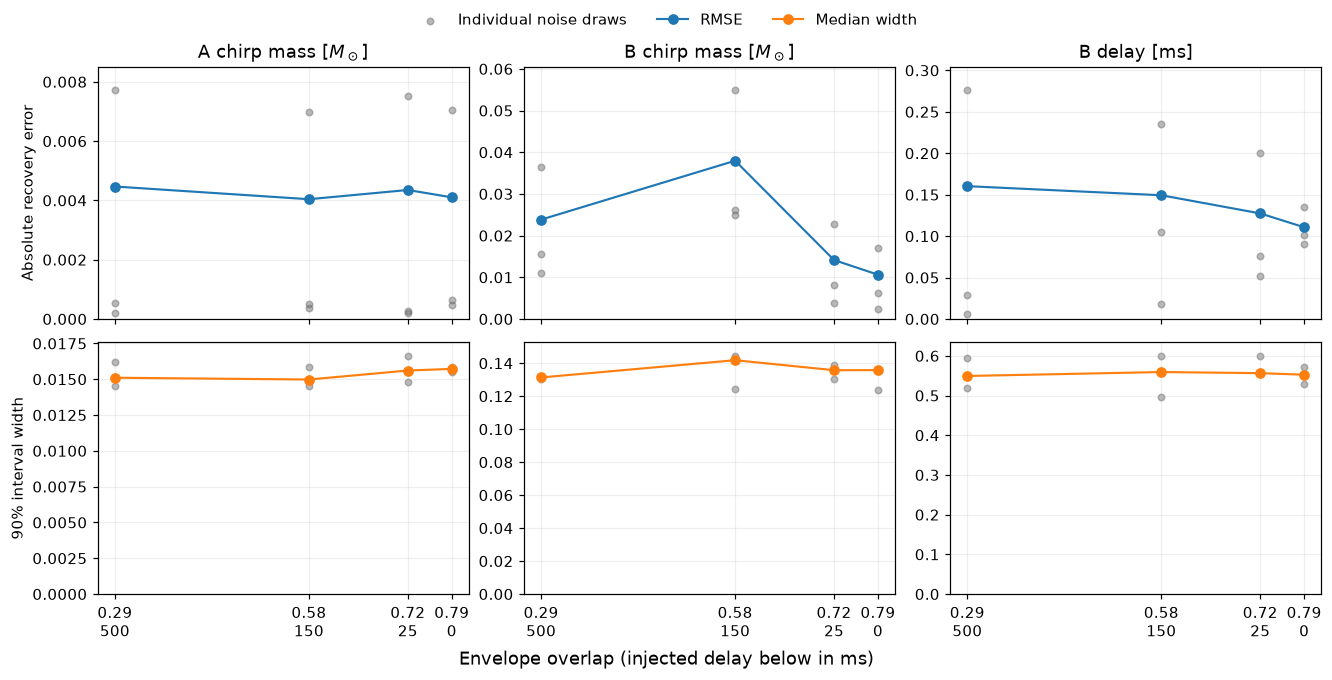

In [11]:
injections = np.column_stack(
    (np.full_like(sweep_delays_s, mass_a), np.full_like(sweep_delays_s, mass_b), sweep_delays_s)
) * display_scale
absolute_errors = np.abs(sweep_quantiles[:, :, 1, :] - injections[:, None, :])
interval_widths = sweep_quantiles[:, :, 2, :] - sweep_quantiles[:, :, 0, :]
rmse = np.sqrt(np.mean(absolute_errors**2, axis=1))
median_widths = np.median(interval_widths, axis=1)

print(f"{'Delay':>8}  {'Overlap':>7}  {'RMSE A':>9}  {'RMSE B':>9}  {'RMSE delay':>10}"
      f"  {'Width A':>9}  {'Width B':>9}  {'Width delay':>11}")
print(f"{'[ms]':>8}  {'':>7}  {'[M_sun]':>9}  {'[M_sun]':>9}  {'[ms]':>10}"
      f"  {'[M_sun]':>9}  {'[M_sun]':>9}  {'[ms]':>11}")
for delay, overlap, errors, widths in zip(sweep_delays_s, sweep_overlaps, rmse, median_widths):
    print(f"{delay * 1000:8.0f}  {overlap:7.3f}  {errors[0]:9.4f}  {errors[1]:9.4f}  {errors[2]:10.4f}"
          f"  {widths[0]:9.4f}  {widths[1]:9.4f}  {widths[2]:11.4f}")

order = np.argsort(sweep_overlaps)
x = sweep_overlaps[order]
tick_labels = [f"{sweep_overlaps[i]:.2f}\n{sweep_delays_s[i] * 1000:g}" for i in order]
fig, axes = plt.subplots(2, 3, figsize=(12, 6.1), sharex=True, layout="constrained")

for p, title in enumerate(labels):
    axes[0, p].set_title(title)
    for row, (per_draw, summary, summary_label, color) in enumerate(
        [(absolute_errors, rmse, "RMSE", "C0"), (interval_widths, median_widths, "Median width", "C1")]
    ):
        ax = axes[row, p]
        ax.scatter(np.repeat(x, len(noise_seeds)), per_draw[order, :, p].ravel(),
                   color="0.40", alpha=0.45, s=18, label="Individual noise draws")
        ax.plot(x, summary[order, p], "o-", color=color, lw=1.4, label=summary_label)
        ax.set_ylim(0, 1.05 * ax.get_ylim()[1])
        ax.grid(alpha=0.2)
        ax.set_xticks(x, tick_labels)

axes[0, 0].set_ylabel("Absolute recovery error")
axes[1, 0].set_ylabel("90% interval width")
fig.supxlabel("Envelope overlap (injected delay below in ms)")
draws_handle, rmse_handle = axes[0, 0].get_legend_handles_labels()[0]
width_handle = axes[1, 0].get_legend_handles_labels()[0][1]
fig.legend(handles=[draws_handle, rmse_handle, width_handle], loc="outside upper center",
           ncols=3, frameon=False)
plt.show()